# Sims genome

A body genotype after Karl Sims, "Evolving Virtual Creatures" (1994). The genome is a small graph of module templates. A template is a brick or a hinge with a tilt and a copy limit: how many copies of it may appear in a row along one chain. A connection says that a copy of its child grows on one face of every copy of its parent, and it may point back at its own parent, so one template can stand for a whole arm. A connection can also carry a mirror flag, which grows a mirrored twin on the opposite side of the body. Node 0 is always the core.

`unfold` turns a genome into the body graph `construct_mjspec_from_graph` builds. In this notebook you write a genome by hand and unfold it, see mirrored tilted limbs come out exact, see the copy limit scale with the maximum number of modules, draw random genomes with and without mirror flags, mutate and cross genomes, and save one to JSON. The pictures are top-down sketches drawn from the geoms (no OpenGL needed), with the core's FRONT pointing up.

In [1]:
# Standard library
from pathlib import Path

# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import networkx as nx
import numpy as np
import numpy.typing as npt
from matplotlib.collections import PolyCollection

In [2]:
# Local libraries
from ariel import console
from ariel.body_phenotypes import (
    ModuleFaces,
    ModuleRotationsIdx,
    ModuleType,
    construct_mjspec_from_graph,
)
from ariel.ec.genotypes.sims import (
    SimsConnection,
    SimsGenome,
    SimsNode,
    crossover,
    graft,
    max_copy_limit,
    mutate,
    random_genome,
    unfold,
)
from ariel.simulators import compile_model

In [3]:
# Settings
SEED = 42
RNG = np.random.default_rng(SEED)
MAX_MODULES = 30
MIRROR = np.array([-1.0, 1.0, 1.0])  # through the core's centre plane
SYMMETRY_TOLERANCE = 1e-3  # metres; the modules round their quaternions
DATA = Path.cwd() / "__data__" / "sims_genome"
DATA.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 60  # keeps the saved notebook small
%config InlineBackend.figure_formats = ["jpeg"]  # half the size of PNG

## Sketches of a body

`corners` builds a body and returns the corners of every geom's box in the core's frame (x to the core's RIGHT, y to its FRONT). `sketch` draws them from above, and `asymmetry` says how far a body is from its own mirror image: for every corner mirrored through the centre plane, the distance to the nearest real corner, the largest of them in metres.

In [4]:
CORNERS = np.array([
    [x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)
])
BOX_FACES = [
    [0, 1, 3, 2],
    [4, 5, 7, 6],
    [0, 1, 5, 4],
    [2, 3, 7, 6],
    [0, 2, 6, 4],
    [1, 3, 7, 5],
]


def corners(graph: nx.DiGraph) -> npt.NDArray[np.float64]:
    model = compile_model(construct_mjspec_from_graph(graph).spec)
    data = mujoco.MjData(model)
    mujoco.mj_forward(model, data)
    boxes = np.array([
        data.geom_xpos[g]
        + (CORNERS * model.geom_size[g]) @ data.geom_xmat[g].reshape(3, 3).T
        for g in range(model.ngeom)
    ])
    core = model.geom_bodyid[0]
    return (boxes - data.xpos[core]) @ data.xmat[core].reshape(3, 3)


def asymmetry(graph: nx.DiGraph) -> float:
    points = corners(graph).reshape(-1, 3)
    return max(
        float(np.min(np.linalg.norm(points - p, axis=1)))
        for p in points * MIRROR
    )


def sketch(graph: nx.DiGraph, axis: plt.Axes, title: str) -> None:
    boxes = corners(graph)
    faces = [box[face][:, :2] for box in boxes for face in BOX_FACES]
    axis.add_collection(
        PolyCollection(
            faces, facecolors="lightgrey", edgecolors="k", linewidths=0.3
        )
    )
    axis.autoscale()
    axis.set_aspect("equal")
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_title(title, fontsize=9)

In [5]:
probe = nx.DiGraph()
probe.add_node(0, type="CORE", rotation="DEG_0")
probe.add_node(1, type="BRICK", rotation="DEG_0")
probe.add_edge(0, 1, face="RIGHT")
probe_corners = corners(probe)
brick_x = probe_corners[-1][:, 0].mean()
console.print(f"brick on the core's RIGHT face, mean x {brick_x:.3f} m")
assert brick_x > 0  # x points to the core's RIGHT
assert asymmetry(probe) > SYMMETRY_TOLERANCE  # one brick on one side

brick on the core's RIGHT face, mean x 0.113 m

## A genome by hand

Template A is a brick with copy limit 3 and a connection to itself on its FRONT face, so it makes an arm of three bricks. The core grows A on its LEFT face with the mirror flag on, so a mirrored arm also grows on its RIGHT face: seven modules from a genome of two nodes. The genome is a pydantic model, and its JSON names every gene.

{
  "nodes": [
    {
      "type": "CORE",
      "rotation": "DEG_0",
      "copy_limit": 1
    },
    {
      "type": "BRICK",
      "rotation": "DEG_0",
      "copy_limit": 3
    }
  ],
  "connections": [
    {
      "parent": 0,
      "child": 1,
      "face": "LEFT",
      "reflect": true,
      "terminal_only": false
    },
    {
      "parent": 1,
      "child": 1,
      "face": "FRONT",
      "reflect": false,
      "terminal_only": false
    }
  ]
}

7 modules; edges [(0, 1, 'LEFT'), (0, 2, 'RIGHT'), (1, 3, 'FRONT'), (2, 4, 'FRONT'), (3, 5, 'FRONT'), (4, 6, 
'FRONT')]

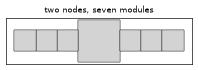

asymmetry 0.00 mm

In [6]:
arm = SimsGenome(
    nodes=(
        SimsNode(type=ModuleType.CORE),
        SimsNode(type=ModuleType.BRICK, copy_limit=3),
    ),
    connections=(
        SimsConnection(parent=0, child=1, face=ModuleFaces.LEFT, reflect=True),
        SimsConnection(parent=1, child=1, face=ModuleFaces.FRONT),
    ),
)
console.print(arm.model_dump_json(indent=2))
arm_body = unfold(arm)
console.print(
    f"{len(arm_body)} modules; edges "
    f"{[(a, b, d['face']) for a, b, d in arm_body.edges(data=True)]}"
)
fig, axis = plt.subplots(figsize=(4, 3))
sketch(arm_body, axis, "two nodes, seven modules")
plt.show()
console.print(f"asymmetry {1000 * asymmetry(arm_body):.2f} mm")

In [7]:
ARM_MODULES = 7
assert len(arm_body) == ARM_MODULES
assert {d["face"] for _, _, d in arm_body.out_edges(0, data=True)} == {
    "LEFT",
    "RIGHT",
}
assert asymmetry(arm_body) < SYMMETRY_TOLERANCE

## Mirrored tilted limbs

A spine of four bricks grows straight out of the core's FRONT face, along the centre plane. Each spine brick grows, on its RIGHT face and mirrored, a hinge tilted 45 degrees with a brick tilted 45 degrees after it. A mirrored brick keeps its tilt (its faces are renamed); a mirrored 45-degree hinge is tilted -45 degrees, a tilt that only mirrored copies use (DESIGN.md Decisions, "Mirroring modules").

21 modules, tilts ['DEG_0', 'DEG_45', 'DEG_MINUS_45']

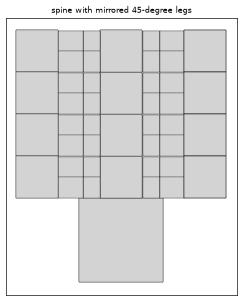

asymmetry 0.05 mm

In [8]:
spine = SimsGenome(
    nodes=(
        SimsNode(type=ModuleType.CORE),
        SimsNode(type=ModuleType.BRICK, copy_limit=4),
        SimsNode(type=ModuleType.HINGE, rotation=ModuleRotationsIdx.DEG_45),
        SimsNode(type=ModuleType.BRICK, rotation=ModuleRotationsIdx.DEG_45),
    ),
    connections=(
        SimsConnection(parent=0, child=1, face=ModuleFaces.FRONT),
        SimsConnection(parent=1, child=1, face=ModuleFaces.FRONT),
        SimsConnection(parent=1, child=2, face=ModuleFaces.RIGHT, reflect=True),
        SimsConnection(parent=2, child=3, face=ModuleFaces.FRONT),
    ),
)
spine_body = unfold(spine)
tilts = sorted({d["rotation"] for _, d in spine_body.nodes(data=True)})
console.print(f"{len(spine_body)} modules, tilts {tilts}")
fig, axis = plt.subplots(figsize=(6, 6))
sketch(spine_body, axis, "spine with mirrored 45-degree legs")
plt.show()
console.print(f"asymmetry {1000 * asymmetry(spine_body):.2f} mm")

In [9]:
SPINE_MODULES = 1 + 4 + 4 * 2 * 2  # core, spine, two 2-module legs per brick
assert len(spine_body) == SPINE_MODULES
assert "DEG_MINUS_45" in tilts
assert asymmetry(spine_body) < SYMMETRY_TOLERANCE

## The copy limit and the maximum number of modules

A template may appear at most its copy limit times along a chain, and never more than a fifth of the maximum number of modules: 6 in a body of 30, 20 in a body of 100. A brick that asks for 50 copies makes an arm of 6 in the first and 20 in the second; a genome that fits keeps its body whatever the maximum.

In [10]:
long_arm = SimsGenome(
    nodes=(
        SimsNode(type=ModuleType.CORE),
        SimsNode(type=ModuleType.BRICK, copy_limit=50),
    ),
    connections=(
        SimsConnection(parent=0, child=1, face=ModuleFaces.FRONT),
        SimsConnection(parent=1, child=1, face=ModuleFaces.FRONT),
    ),
)
lengths = {m: len(unfold(long_arm, m)) - 1 for m in (MAX_MODULES, 100)}
console.print(f"arm length by maximum: {lengths}")
fixed = {m: len(unfold(arm, m)) for m in (MAX_MODULES, 100)}
console.print(f"the 3-brick arms by maximum: {fixed}")

arm length by maximum: {30: 6, 100: 20}

the 3-brick arms by maximum: {30: 7, 100: 7}

In [11]:
assert lengths == {
    MAX_MODULES: max_copy_limit(MAX_MODULES),
    100: max_copy_limit(100),
}
assert fixed == {MAX_MODULES: ARM_MODULES, 100: ARM_MODULES}

## Random genomes

`random_genome` draws the core and 1 to 4 templates, reaches every template from the core or an earlier one, adds a few more connections, and draws again until the body has at least 10 modules. With `mirror=True` half the connections carry the mirror flag; with `mirror=False` none do. A flag adds a twin only on a side face of a module on the centre plane, so with flags on a body is symmetric only as far as its flags reach; some of the eight below are not. Eight bodies of each kind, then the sizes of 200.

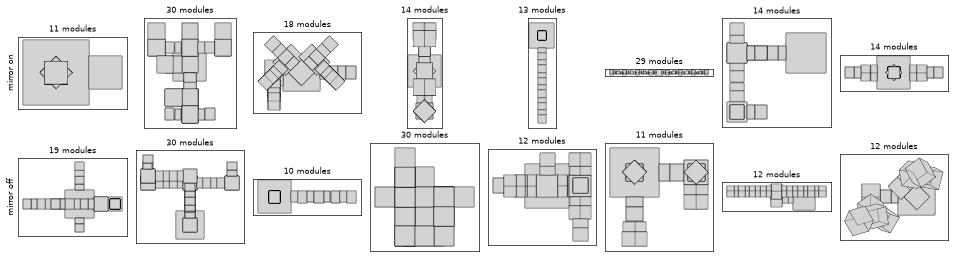

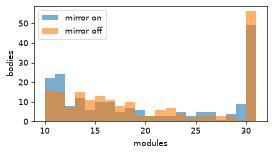

mirror on: median 18 modules

mirror off: median 18 modules

In [12]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, mirror in enumerate((True, False)):
    for axis in axes[row]:
        body = unfold(random_genome(RNG, mirror=mirror))
        sketch(body, axis, f"{len(body)} modules")
    axes[row][0].set_ylabel(f"mirror {'on' if mirror else 'off'}")
plt.tight_layout()
plt.show()

sizes = {
    mirror: [len(unfold(random_genome(RNG, mirror=mirror))) for _ in range(200)]
    for mirror in (True, False)
}
fig, axis = plt.subplots(figsize=(5, 2.5))
for mirror, values in sizes.items():
    axis.hist(
        values,
        bins=range(10, 32),
        alpha=0.6,
        label=f"mirror {'on' if mirror else 'off'}",
    )
axis.set_xlabel("modules")
axis.set_ylabel("bodies")
axis.legend()
plt.show()
for mirror, values in sizes.items():
    label = "on" if mirror else "off"
    console.print(f"mirror {label}: median {np.median(values):.0f} modules")

In [13]:
MIN_MODULES = 10
for values in sizes.values():
    assert min(values) >= MIN_MODULES
    assert max(values) <= MAX_MODULES

## Mutation and crossover

`mutate` applies one of Sims's operators, picked among those that apply: change a template or a connection, add or remove one, or drop the templates nothing reaches. It always returns a genome that differs from the one it was given. `crossover` lines two genomes' templates up and cuts them at one point; `graft` points one of the first genome's connections at a template of the second.

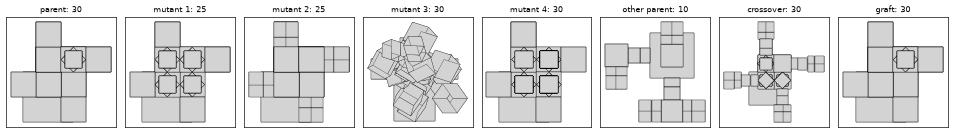

In [14]:
parent = random_genome(RNG)
other = random_genome(RNG)
mutants = [mutate(parent, RNG) for _ in range(4)]
children = {
    "crossover": crossover(parent, other, RNG),
    "graft": graft(parent, other, RNG),
}
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
panels = [
    ("parent", parent),
    *((f"mutant {i + 1}", m) for i, m in enumerate(mutants)),
    ("other parent", other),
    *children.items(),
]
for axis, (title, genome) in zip(axes, panels, strict=True):
    body = unfold(genome)
    sketch(body, axis, f"{title}: {len(body)}")
plt.tight_layout()
plt.show()

In [15]:
assert all(mutant != parent for mutant in mutants)
for genome in (*mutants, *children.values()):
    assert len(unfold(genome)) >= 1
assert children["crossover"].nodes[0] == SimsNode(type=ModuleType.CORE)

## Save and load

A genome is saved as JSON and loads back equal.

In [16]:
path = DATA / "spine.json"
spine.save_json(path)
console.print(f"{path.name}: {path.stat().st_size} bytes")
loaded = SimsGenome.load_json(path)

spine.json: 886 bytes

In [17]:
assert loaded == spine
assert unfold(loaded).edges == spine_body.edges